In [ ]:
# STEP 1: Set up Pix2Pix building outline-to-photo project

import os
import random
import zipfile
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create project folders
PROJECT_DIR = Path("/content/Pix2Pix_Project")
DATA_DIR = PROJECT_DIR / "building_photos"
OUTLINE_DIR = PROJECT_DIR / "outlines"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
SAMPLE_DIR = PROJECT_DIR / "samples"

for folder in [DATA_DIR, OUTLINE_DIR, CHECKPOINT_DIR, SAMPLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Fixed image size for training
IMAGE_SIZE = 256

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("Pix2Pix project folders created successfully!")
print("Device:", device)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nProject location:", PROJECT_DIR)
print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("\nNext: upload your building-photo dataset as a ZIP file.")

Pix2Pix project folders created successfully!
Device: cuda
GPU available: True
GPU: Tesla T4

Project location: /content/Pix2Pix_Project
Image size: 256 x 256

Next: upload your building-photo dataset as a ZIP file.


Extracting dataset...
Prepared photo/outline pairs: 606


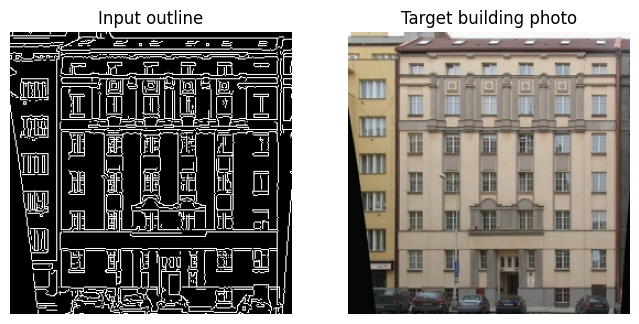

In [ ]:

# CELL 2: Automatically download and prepare the facade dataset

import urllib.request
import tarfile
from pathlib import Path
from PIL import Image
import cv2
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/Pix2Pix_Project")
DATA_DIR = PROJECT_DIR / "building_photos"
OUTLINE_DIR = PROJECT_DIR / "outlines"

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTLINE_DIR.mkdir(parents=True, exist_ok=True)

# Download the public CMP Facades dataset
url = "https://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz"
archive = PROJECT_DIR / "facades.tar.gz"
extract_dir = PROJECT_DIR / "facades_dataset"
extract_dir.mkdir(parents=True, exist_ok=True)

if not any(extract_dir.rglob("*.jpg")):
    print("Downloading facade dataset...")
    urllib.request.urlretrieve(url, archive)

    print("Extracting dataset...")
    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(extract_dir, filter="data")

# The dataset images contain a photo and a label-map side by side.
image_paths = sorted(
    p for p in extract_dir.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

count = 0

for path in image_paths:
    try:
        with Image.open(path) as im:
            im = im.convert("RGB")
            w, h = im.size

            if w < 2 or h < 2:
                continue

            # Standard Pix2Pix facades format: photo on left,
            # label map on right.
            photo = im.crop((0, 0, w // 2, h))
            photo = photo.resize((256, 256), Image.Resampling.LANCZOS)

        photo_np = np.array(photo)
        gray = cv2.cvtColor(photo_np, cv2.COLOR_RGB2GRAY)
        edges = cv2.Canny(gray, 80, 160)
        outline_np = np.repeat(edges[:, :, None], 3, axis=2)

        name = f"building_{count:04d}.png"
        Image.fromarray(photo_np).save(DATA_DIR / name)
        Image.fromarray(outline_np).save(OUTLINE_DIR / name)
        count += 1

    except Exception as e:
        print("Skipped:", path.name, str(e))

print("Prepared photo/outline pairs:", count)

if count == 0:
    raise RuntimeError("No images were prepared. Please share the error output.")

# Show one example
photo = Image.open(DATA_DIR / "building_0000.png")
outline = Image.open(OUTLINE_DIR / "building_0000.png")

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(outline)
plt.title("Input outline")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(photo)
plt.title("Target building photo")
plt.axis("off")
plt.show()


Device: cuda
Training pairs: 606
Epochs: 100
Epoch 001/100 | G: 42.301 | D: 0.260


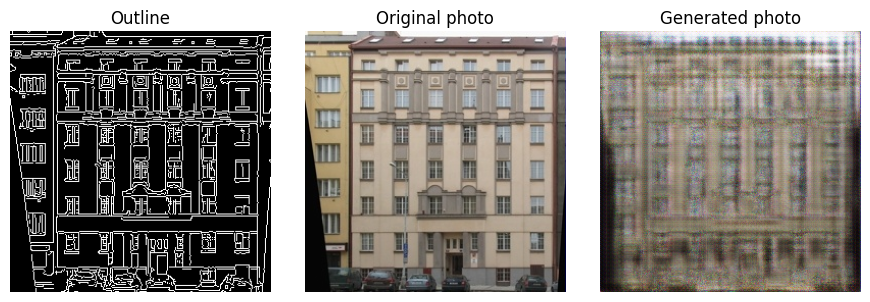

Epoch 002/100 | G: 41.699 | D: 0.267
Epoch 003/100 | G: 41.013 | D: 0.292
Epoch 004/100 | G: 39.624 | D: 0.301
Epoch 005/100 | G: 38.323 | D: 0.284


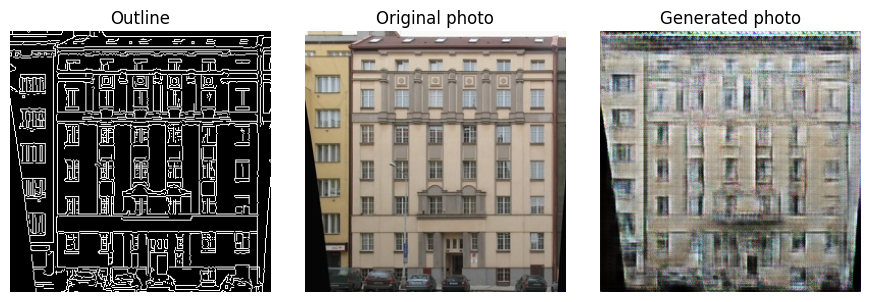

Epoch 006/100 | G: 36.586 | D: 0.272
Epoch 007/100 | G: 34.676 | D: 0.291
Epoch 008/100 | G: 33.145 | D: 0.295
Epoch 009/100 | G: 31.280 | D: 0.316
Epoch 010/100 | G: 29.526 | D: 0.328


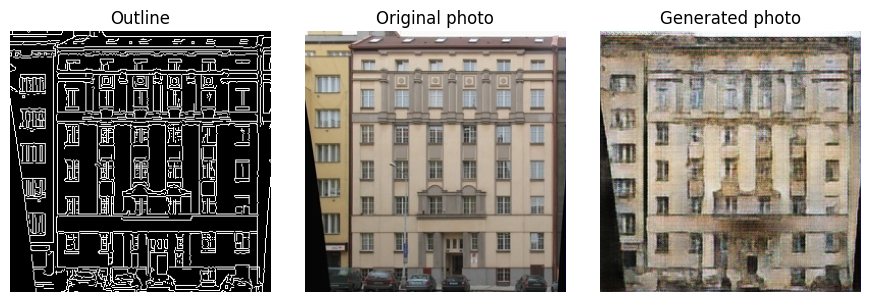

Epoch 011/100 | G: 28.182 | D: 0.347
Epoch 012/100 | G: 26.798 | D: 0.348
Epoch 013/100 | G: 25.729 | D: 0.362
Epoch 014/100 | G: 24.711 | D: 0.366
Epoch 015/100 | G: 23.844 | D: 0.353


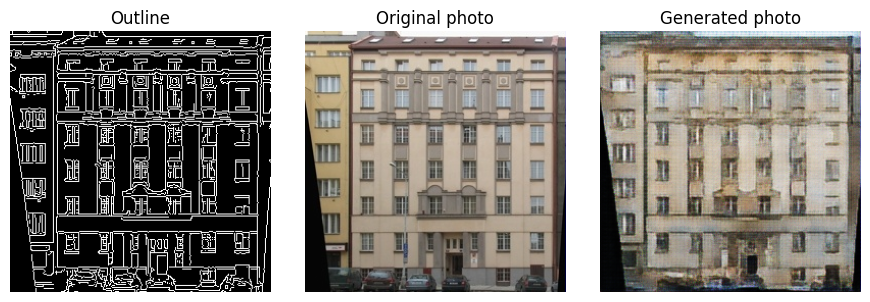

Epoch 016/100 | G: 23.032 | D: 0.360
Epoch 017/100 | G: 22.416 | D: 0.352
Epoch 018/100 | G: 21.517 | D: 0.370
Epoch 019/100 | G: 20.941 | D: 0.349
Epoch 020/100 | G: 20.357 | D: 0.354


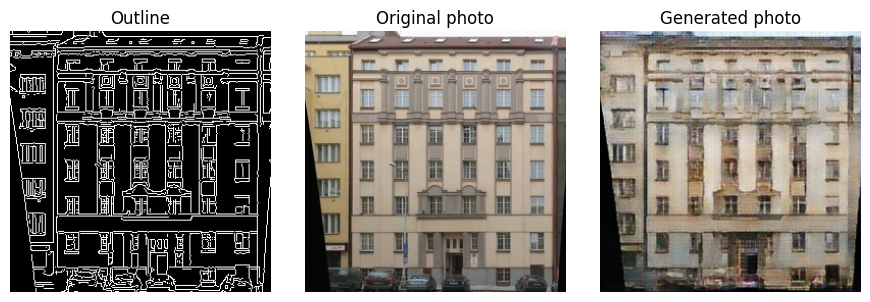

Epoch 021/100 | G: 19.742 | D: 0.355
Epoch 022/100 | G: 19.528 | D: 0.350
Epoch 023/100 | G: 19.158 | D: 0.330
Epoch 024/100 | G: 18.861 | D: 0.348
Epoch 025/100 | G: 18.381 | D: 0.338


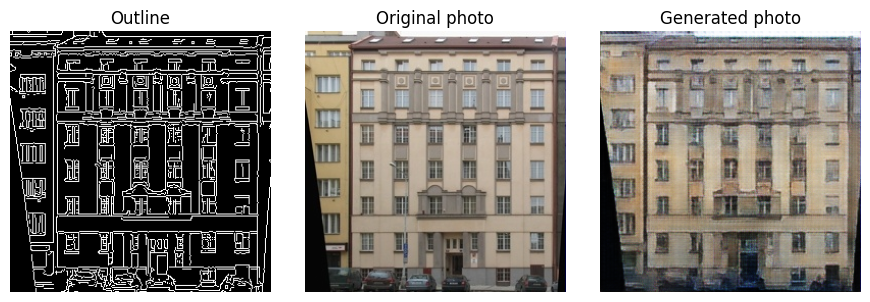

Epoch 026/100 | G: 18.282 | D: 0.346
Epoch 027/100 | G: 17.906 | D: 0.339
Epoch 028/100 | G: 17.548 | D: 0.362
Epoch 029/100 | G: 17.378 | D: 0.344
Epoch 030/100 | G: 17.180 | D: 0.352


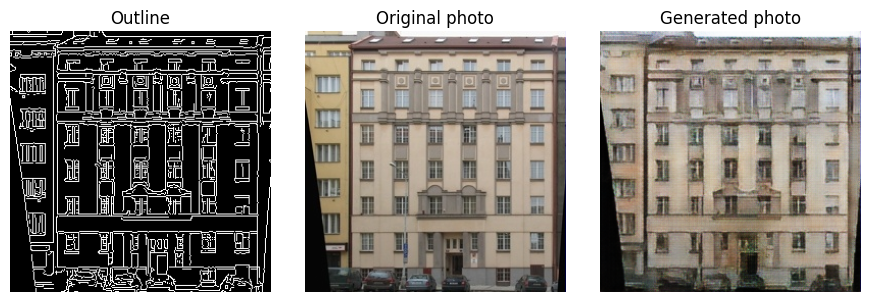

Epoch 031/100 | G: 16.983 | D: 0.345
Epoch 032/100 | G: 16.871 | D: 0.342
Epoch 033/100 | G: 16.535 | D: 0.344
Epoch 034/100 | G: 16.536 | D: 0.334
Epoch 035/100 | G: 16.475 | D: 0.336


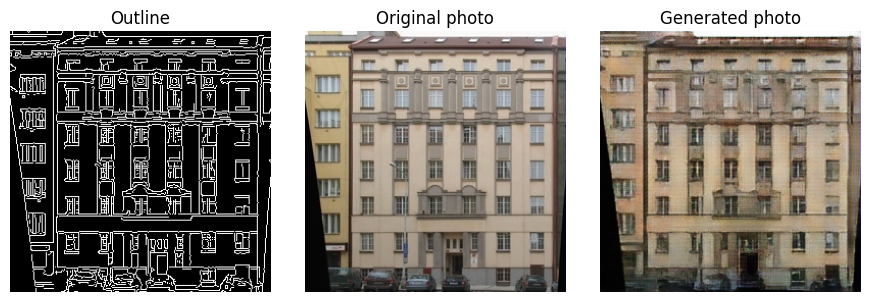

Epoch 036/100 | G: 16.029 | D: 0.355
Epoch 037/100 | G: 15.851 | D: 0.340
Epoch 038/100 | G: 15.807 | D: 0.354
Epoch 039/100 | G: 15.508 | D: 0.368
Epoch 040/100 | G: 15.490 | D: 0.333


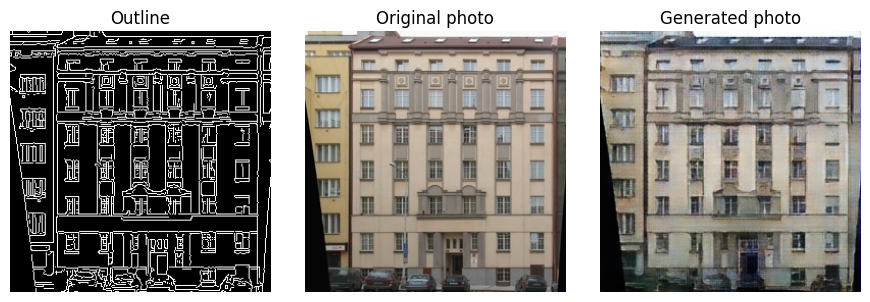

Epoch 041/100 | G: 15.225 | D: 0.365
Epoch 042/100 | G: 15.238 | D: 0.373
Epoch 043/100 | G: 14.954 | D: 0.350
Epoch 044/100 | G: 14.820 | D: 0.370
Epoch 045/100 | G: 14.718 | D: 0.375


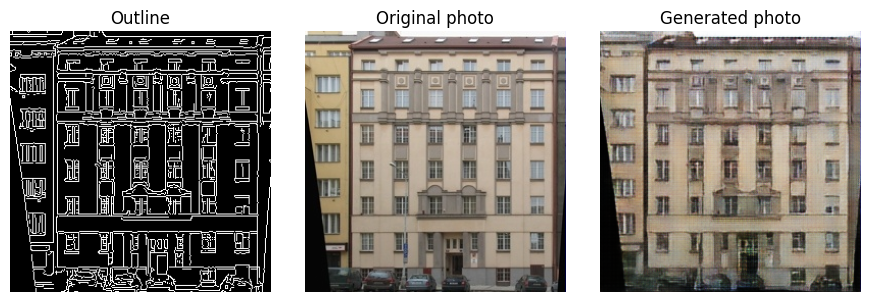

Epoch 046/100 | G: 14.713 | D: 0.366
Epoch 047/100 | G: 14.423 | D: 0.385
Epoch 048/100 | G: 14.336 | D: 0.371
Epoch 049/100 | G: 14.319 | D: 0.362
Epoch 050/100 | G: 14.189 | D: 0.390


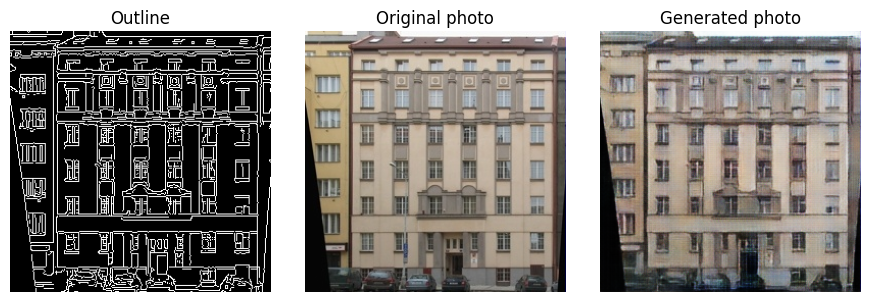

Epoch 051/100 | G: 13.922 | D: 0.398
Epoch 052/100 | G: 13.896 | D: 0.386
Epoch 053/100 | G: 13.956 | D: 0.375
Epoch 054/100 | G: 13.671 | D: 0.397
Epoch 055/100 | G: 13.621 | D: 0.397


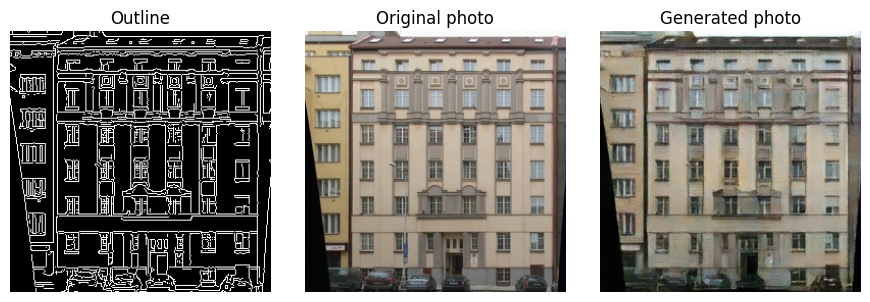

Epoch 056/100 | G: 13.539 | D: 0.407
Epoch 057/100 | G: 13.512 | D: 0.388
Epoch 058/100 | G: 13.318 | D: 0.424
Epoch 059/100 | G: 13.237 | D: 0.407
Epoch 060/100 | G: 13.153 | D: 0.405


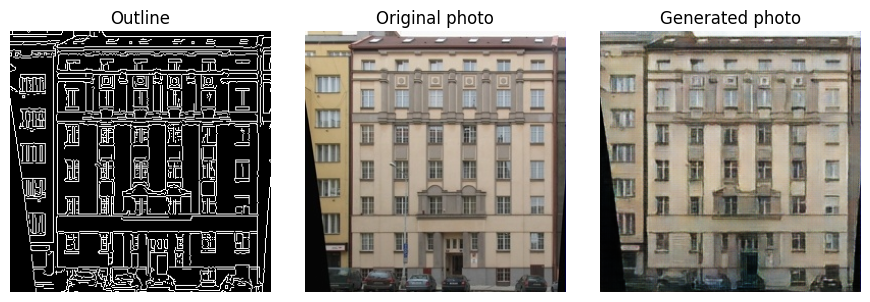

Epoch 061/100 | G: 13.084 | D: 0.429
Epoch 062/100 | G: 12.976 | D: 0.421
Epoch 063/100 | G: 12.959 | D: 0.400
Epoch 064/100 | G: 12.880 | D: 0.428
Epoch 065/100 | G: 12.691 | D: 0.421


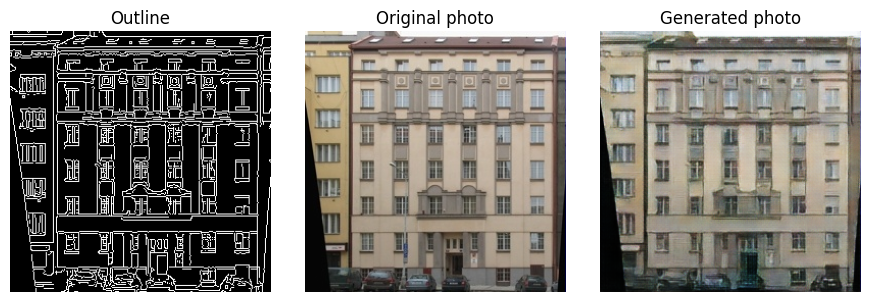

Epoch 066/100 | G: 12.699 | D: 0.437
Epoch 067/100 | G: 12.559 | D: 0.436
Epoch 068/100 | G: 12.478 | D: 0.422
Epoch 069/100 | G: 12.464 | D: 0.435
Epoch 070/100 | G: 12.355 | D: 0.447


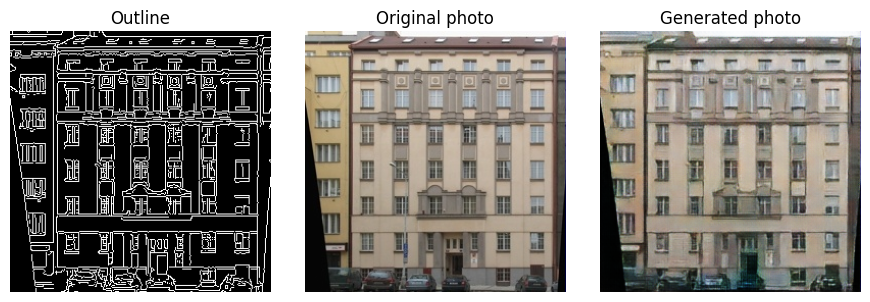

Epoch 071/100 | G: 12.286 | D: 0.447
Epoch 072/100 | G: 12.256 | D: 0.428
Epoch 073/100 | G: 12.227 | D: 0.432
Epoch 074/100 | G: 12.163 | D: 0.449
Epoch 075/100 | G: 11.961 | D: 0.461


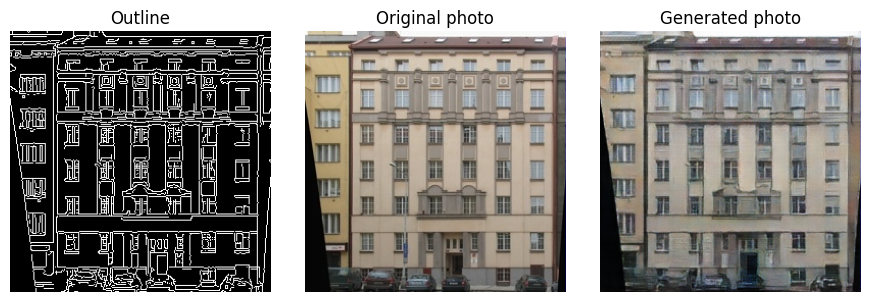

Epoch 076/100 | G: 11.886 | D: 0.462
Epoch 077/100 | G: 11.765 | D: 0.450
Epoch 078/100 | G: 11.831 | D: 0.457
Epoch 079/100 | G: 11.684 | D: 0.458
Epoch 080/100 | G: 11.714 | D: 0.442


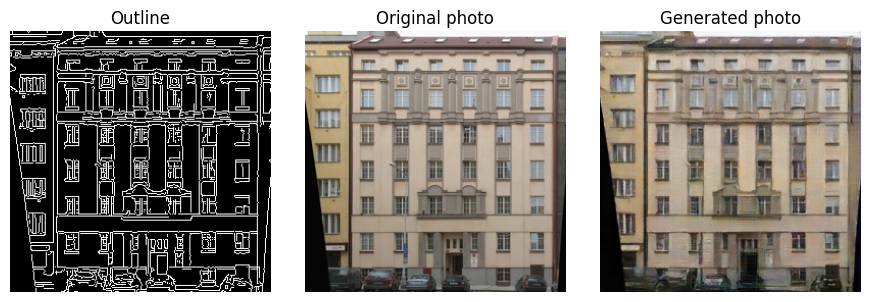

Epoch 081/100 | G: 11.679 | D: 0.459
Epoch 082/100 | G: 11.539 | D: 0.472
Epoch 083/100 | G: 11.451 | D: 0.465
Epoch 084/100 | G: 11.494 | D: 0.444
Epoch 085/100 | G: 11.463 | D: 0.454


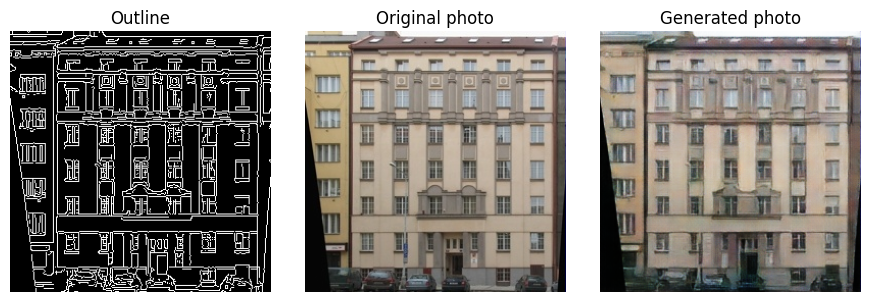

Epoch 086/100 | G: 11.396 | D: 0.466
Epoch 087/100 | G: 11.250 | D: 0.470
Epoch 088/100 | G: 11.374 | D: 0.441
Epoch 089/100 | G: 11.385 | D: 0.453
Epoch 090/100 | G: 11.836 | D: 0.399


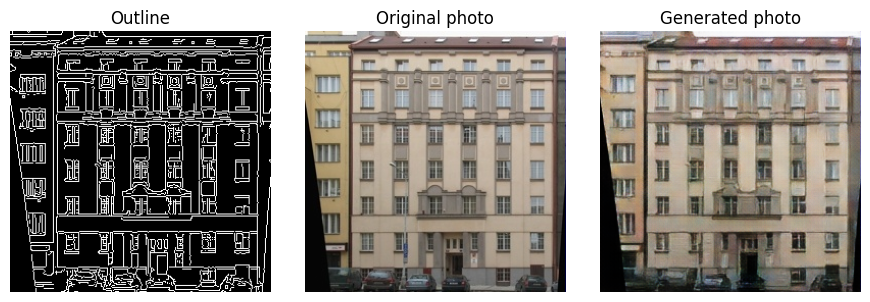

Epoch 091/100 | G: 11.928 | D: 0.406
Epoch 092/100 | G: 11.989 | D: 0.361
Epoch 093/100 | G: 12.040 | D: 0.391
Epoch 094/100 | G: 11.878 | D: 0.391
Epoch 095/100 | G: 11.638 | D: 0.403


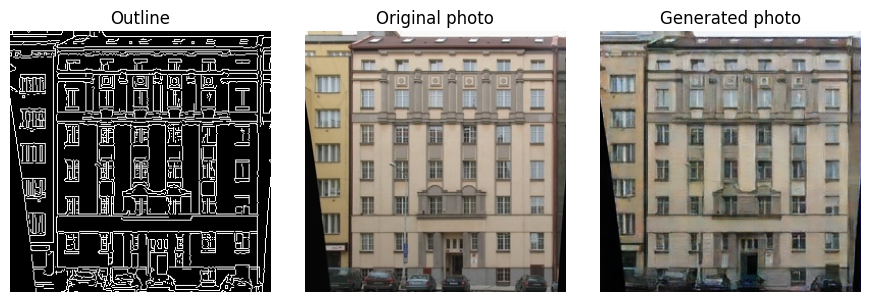

Epoch 096/100 | G: 11.695 | D: 0.396
Epoch 097/100 | G: 11.481 | D: 0.423
Epoch 098/100 | G: 11.536 | D: 0.423
Epoch 099/100 | G: 11.358 | D: 0.417
Epoch 100/100 | G: 11.575 | D: 0.404


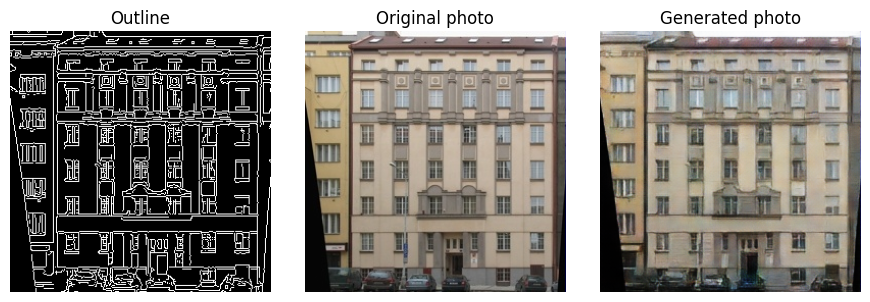

Training complete. Final model saved.


In [ ]:

# CELL 3: Define and train Pix2Pix (U-Net + PatchGAN)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import random
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/Pix2Pix_Project")
DATA_DIR = PROJECT_DIR / "building_photos"
OUTLINE_DIR = PROJECT_DIR / "outlines"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
SAMPLE_DIR = PROJECT_DIR / "samples"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 256
EPOCHS = 100
BATCH_SIZE = 1
LR = 0.0002
LAMBDA_L1 = 100

# Dataset: each outline is paired with its exact original photo
class BuildingDataset(Dataset):
    def __init__(self):
        self.names = sorted(
            p.name for p in OUTLINE_DIR.glob("*.png")
            if (DATA_DIR / p.name).exists()
        )
        if len(self.names) < 2:
            raise RuntimeError(
                f"Only {len(self.names)} pairs found. Run the dataset cell first."
            )
        self.transform = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]
        outline = Image.open(OUTLINE_DIR / name).convert("RGB")
        photo = Image.open(DATA_DIR / name).convert("RGB")
        return self.transform(outline), self.transform(photo)

# U-Net generator
def down_block(in_ch, out_ch, normalize=True):
    layers = [nn.Conv2d(in_ch, out_ch, 4, 2, 1, bias=False)]
    if normalize:
        layers.append(nn.BatchNorm2d(out_ch))
    layers.append(nn.LeakyReLU(0.2, inplace=True))
    return nn.Sequential(*layers)

def up_block(in_ch, out_ch, dropout=False):
    layers = [
        nn.ConvTranspose2d(in_ch, out_ch, 4, 2, 1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True)
    ]
    if dropout:
        layers.append(nn.Dropout(0.5))
    return nn.Sequential(*layers)

class UNetGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.d1 = down_block(3, 64, False)
        self.d2 = down_block(64, 128)
        self.d3 = down_block(128, 256)
        self.d4 = down_block(256, 512)
        self.d5 = down_block(512, 512)
        self.d6 = down_block(512, 512)
        self.d7 = down_block(512, 512)
        self.bottleneck = nn.Sequential(
            nn.Conv2d(512, 512, 4, 2, 1),
            nn.ReLU(inplace=True)
        )

        self.u1 = up_block(512, 512, True)
        self.u2 = up_block(1024, 512, True)
        self.u3 = up_block(1024, 512, True)
        self.u4 = up_block(1024, 512)
        self.u5 = up_block(1024, 256)
        self.u6 = up_block(512, 128)
        self.u7 = up_block(256, 64)
        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, 3, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, x):
        d1 = self.d1(x)
        d2 = self.d2(d1)
        d3 = self.d3(d2)
        d4 = self.d4(d3)
        d5 = self.d5(d4)
        d6 = self.d6(d5)
        d7 = self.d7(d6)
        b = self.bottleneck(d7)

        u1 = self.u1(b)
        u2 = self.u2(torch.cat([u1, d7], dim=1))
        u3 = self.u3(torch.cat([u2, d6], dim=1))
        u4 = self.u4(torch.cat([u3, d5], dim=1))
        u5 = self.u5(torch.cat([u4, d4], dim=1))
        u6 = self.u6(torch.cat([u5, d3], dim=1))
        u7 = self.u7(torch.cat([u6, d2], dim=1))
        return self.final(torch.cat([u7, d1], dim=1))

# 70x70 PatchGAN discriminator
class PatchDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        def block(a, b, norm=True):
            layers = [nn.Conv2d(a, b, 4, 2, 1)]
            if norm:
                layers.append(nn.BatchNorm2d(b))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *block(6, 64, False),
            *block(64, 128),
            *block(128, 256),
            nn.Conv2d(256, 512, 4, 1, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, 1, 4, 1, 1)
        )

    def forward(self, outline, photo):
        return self.model(torch.cat([outline, photo], dim=1))

# Initialize
dataset = BuildingDataset()
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                    num_workers=2, pin_memory=torch.cuda.is_available())

G = UNetGenerator().to(device)
D = PatchDiscriminator().to(device)

criterion_GAN = nn.BCEWithLogitsLoss()
criterion_L1 = nn.L1Loss()
optimizer_G = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
optimizer_D = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))

print("Device:", device)
print("Training pairs:", len(dataset))
print("Epochs:", EPOCHS)

# Resume automatically from latest checkpoint, if one exists
latest = CHECKPOINT_DIR / "last.pt"
start_epoch = 0

if latest.exists():
    checkpoint = torch.load(latest, map_location=device, weights_only=False)
    G.load_state_dict(checkpoint["G"])
    D.load_state_dict(checkpoint["D"])
    optimizer_G.load_state_dict(checkpoint["optimizer_G"])
    optimizer_D.load_state_dict(checkpoint["optimizer_D"])
    start_epoch = checkpoint["epoch"]
    print("Resuming after epoch", start_epoch)

for epoch in range(start_epoch, EPOCHS):
    G.train()
    D.train()
    total_G, total_D = 0.0, 0.0

    for outlines, real_photos in loader:
        outlines = outlines.to(device)
        real_photos = real_photos.to(device)

        # Train discriminator
        with torch.no_grad():
            fake_photos = G(outlines)

        optimizer_D.zero_grad()
        real_pred = D(outlines, real_photos)
        fake_pred = D(outlines, fake_photos)
        loss_D = (
            criterion_GAN(real_pred, torch.ones_like(real_pred)) +
            criterion_GAN(fake_pred, torch.zeros_like(fake_pred))
        ) * 0.5
        loss_D.backward()
        optimizer_D.step()

        # Train generator
        optimizer_G.zero_grad()
        fake_photos = G(outlines)
        pred_fake = D(outlines, fake_photos)
        loss_G_GAN = criterion_GAN(pred_fake, torch.ones_like(pred_fake))
        loss_G_L1 = criterion_L1(fake_photos, real_photos) * LAMBDA_L1
        loss_G = loss_G_GAN + loss_G_L1
        loss_G.backward()
        optimizer_G.step()

        total_G += loss_G.item()
        total_D += loss_D.item()

    # Save full checkpoint after every epoch
    torch.save({
        "epoch": epoch + 1,
        "G": G.state_dict(),
        "D": D.state_dict(),
        "optimizer_G": optimizer_G.state_dict(),
        "optimizer_D": optimizer_D.state_dict()
    }, latest)

    # Save generator-only weights for quick demonstration
    torch.save(G.state_dict(), CHECKPOINT_DIR / "generator_latest.pt")

    print(
        f"Epoch {epoch+1:03d}/{EPOCHS} | "
        f"G: {total_G/len(loader):.3f} | "
        f"D: {total_D/len(loader):.3f}"
    )

    # Save a preview every 5 epochs
    if (epoch + 1) % 5 == 0 or epoch == 0:
        G.eval()
        with torch.no_grad():
            preview_input, preview_target = dataset[0]
            preview = G(preview_input.unsqueeze(0).to(device))
            preview = ((preview[0].cpu() + 1) / 2).clamp(0, 1)

        plt.figure(figsize=(9, 3))
        plt.subplot(1, 3, 1)
        plt.imshow(((preview_input + 1) / 2).permute(1, 2, 0))
        plt.title("Outline")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(((preview_target + 1) / 2).permute(1, 2, 0))
        plt.title("Original photo")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(preview.permute(1, 2, 0))
        plt.title("Generated photo")
        plt.axis("off")
        plt.tight_layout()
        plt.savefig(SAMPLE_DIR / f"epoch_{epoch+1:03d}.png")
        plt.show()
        plt.close()

# Final weights
torch.save(G.state_dict(), CHECKPOINT_DIR / "generator_final.pt")
print("Training complete. Final model saved.")


In [ ]:

# CELL 4: Save and download the complete Pix2Pix project

from pathlib import Path
import zipfile
from google.colab import files
import os

PROJECT_DIR = Path("/content/Pix2Pix_Project")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
SAMPLE_DIR = PROJECT_DIR / "samples"

# Check that training produced a model
model_path = CHECKPOINT_DIR / "generator_final.pt"
latest_path = CHECKPOINT_DIR / "last.pt"

if not model_path.exists() and not latest_path.exists():
    raise FileNotFoundError(
        "No saved checkpoint found. Check whether training completed."
    )

# Create a ZIP backup of the project
zip_path = Path("/content/Pix2Pix_Project_Backup.zip")

print("Creating project backup...")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in PROJECT_DIR.rglob("*"):
        if path.is_file() and path != zip_path:
            # Avoid packaging the downloaded dataset archive
            if path.name == "facades.tar.gz":
                continue
            z.write(path, path.relative_to(PROJECT_DIR.parent))

print(f"Backup created: {zip_path}")
print(f"ZIP size: {zip_path.stat().st_size / (1024**2):.1f} MB")

# Download it to your computer
files.download(str(zip_path))


Creating project backup...
Backup created: /content/Pix2Pix_Project_Backup.zip
ZIP size: 1037.8 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from pathlib import Path
import shutil

PROJECT_DIR = Path("/content/Pix2Pix_Project")
DRIVE_DIR = Path("/content/drive/MyDrive/Pix2Pix_Project")

DRIVE_DIR.mkdir(parents=True, exist_ok=True)

# Copy checkpoints, generated samples, and dataset
for folder_name in [
    "checkpoints",
    "samples",
    "building_photos",
    "outlines"
]:
    source = PROJECT_DIR / folder_name
    destination = DRIVE_DIR / folder_name

    if source.exists():
        shutil.copytree(source, destination, dirs_exist_ok=True)
        print("Saved:", folder_name)

print("\nProject files copied to Google Drive.")
print("Location: My Drive / Pix2Pix_Project")


Saved: checkpoints
Saved: samples
Saved: building_photos
Saved: outlines

Project files copied to Google Drive.
Location: My Drive / Pix2Pix_Project


In [ ]:

from pathlib import Path

drive_project = Path("/content/drive/MyDrive/Pix2Pix_Project")

print("Checking saved project...\n")

for folder in ["checkpoints", "samples"]:
    path = drive_project / folder
    print(f"\n{folder.upper()}:")

    if path.exists():
        for file in path.iterdir():
            if file.is_file():
                size_mb = file.stat().st_size / (1024 * 1024)
                print(f"  {file.name} — {size_mb:.1f} MB")
    else:
        print("  Folder not found")

print("\nCheck complete.")


Checking saved project...


CHECKPOINTS:
  last.pt — 654.5 MB
  generator_final.pt — 207.6 MB
  generator_latest.pt — 207.6 MB

SAMPLES:
  epoch_085.png — 0.3 MB
  epoch_055.png — 0.3 MB
  epoch_075.png — 0.3 MB
  epoch_025.png — 0.3 MB
  epoch_100.png — 0.3 MB
  epoch_070.png — 0.3 MB
  epoch_045.png — 0.3 MB
  epoch_001.png — 0.3 MB
  epoch_030.png — 0.3 MB
  epoch_050.png — 0.3 MB
  epoch_040.png — 0.3 MB
  epoch_080.png — 0.3 MB
  epoch_015.png — 0.3 MB
  epoch_035.png — 0.3 MB
  epoch_005.png — 0.3 MB
  epoch_010.png — 0.3 MB
  epoch_060.png — 0.3 MB
  epoch_095.png — 0.3 MB
  epoch_020.png — 0.3 MB
  epoch_090.png — 0.3 MB
  epoch_065.png — 0.3 MB

Check complete.


In [ ]:

# CELL 5: Load the trained Pix2Pix generator from Google Drive

from pathlib import Path
import torch
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt

DRIVE_DIR = Path("/content/drive/MyDrive/Pix2Pix_Project")
MODEL_PATH = DRIVE_DIR / "checkpoints" / "generator_final.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

print("Model file found:", MODEL_PATH)
print("Device:", device)
print("Next, we will load the saved weights into the same U-Net architecture.")


Model file found: /content/drive/MyDrive/Pix2Pix_Project/checkpoints/generator_final.pt
Device: cuda
Next, we will load the saved weights into the same U-Net architecture.


In [ ]:

# CELL 5: Load the trained Pix2Pix generator from Google Drive

from pathlib import Path
import torch
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt

DRIVE_DIR = Path("/content/drive/MyDrive/Pix2Pix_Project")
MODEL_PATH = DRIVE_DIR / "checkpoints" / "generator_final.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

print("Model file found:", MODEL_PATH)
print("Device:", device)
print("Next, we will load the saved weights into the same U-Net architecture.")


Model file found: /content/drive/MyDrive/Pix2Pix_Project/checkpoints/generator_final.pt
Device: cuda
Next, we will load the saved weights into the same U-Net architecture.


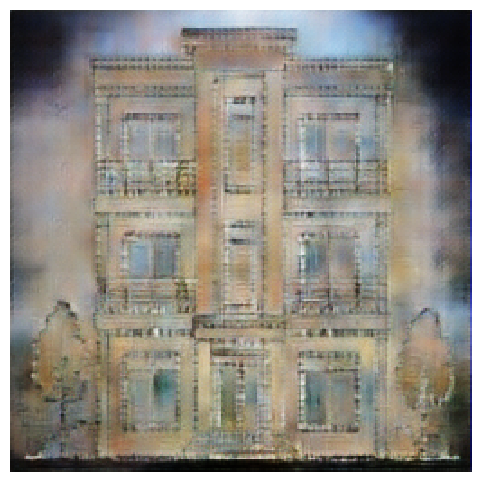

Saved to /content/generated_building_sharp.png


In [ ]:
import torch
import matplotlib.pyplot as plt
from PIL import Image

G.eval()

with torch.inference_mode():
    prediction = G(input_tensor.to(device))

# Convert model output from [-1, 1] to [0, 255]
prediction = prediction[0].detach().cpu().float()
prediction = ((prediction.clamp(-1, 1) + 1) * 127.5)
prediction = prediction.byte().permute(1, 2, 0).numpy()

# Save at native model resolution
result = Image.fromarray(prediction)
result.save("/content/generated_building_sharp.png")

plt.figure(figsize=(6, 6))
plt.imshow(result, interpolation="nearest")
plt.axis("off")
plt.show()

print("Saved to /content/generated_building_sharp.png")

In [ ]:
import numpy as np

print("Input shape:", input_tensor.shape)
print("Output shape:", prediction.shape)
print("Output pixel range:", prediction.min(), "to", prediction.max())
print("Output standard deviation:", round(float(np.std(prediction)), 2))

Input shape: torch.Size([1, 3, 256, 256])
Output shape: (256, 256, 3)
Output pixel range: 1 to 242
Output standard deviation: 43.91


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.lower().endswith((".png", ".jpg", ".jpeg")):
            print(os.path.join(root, f))

/content/generated_building_sharp.png
/content/testhome.png
/content/Screenshot 2026-10-16 165231.png
/content/whatever.png
/content/building.jpg
/content/drawinghome.png
/content/homeeee.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_085.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_055.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_075.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_025.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_100.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_070.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_045.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_001.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_030.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_050.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_040.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_080.png
/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_015.png
/content/drive/

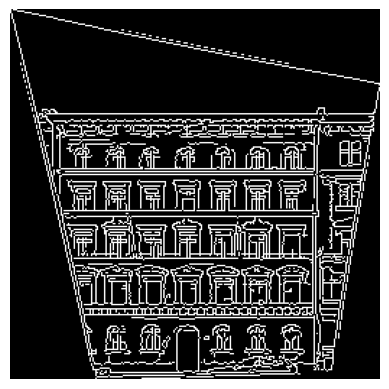

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

path = "/content/drive/MyDrive/Pix2Pix_Project/outlines/building_0511.png"

img = Image.open(path)
plt.imshow(img)
plt.axis("off")
plt.show()

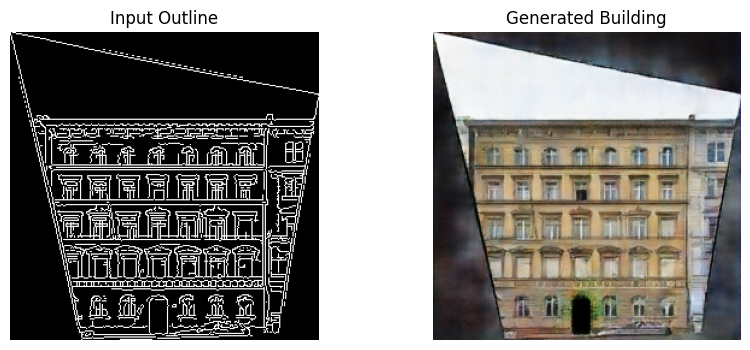

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import torch
import numpy as np

path = "/content/drive/MyDrive/Pix2Pix_Project/outlines/building_0511.png"

img = Image.open(path).convert("RGB").resize((256, 256))

# Prepare input for Pix2Pix
arr = np.array(img).astype(np.float32) / 127.5 - 1.0
input_tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)

# Generate building
G.eval()
with torch.no_grad():
    prediction = G(input_tensor.to(device))

prediction = prediction[0].detach().cpu()
prediction = ((prediction.clamp(-1, 1) + 1) * 127.5)
prediction = prediction.byte().permute(1, 2, 0).numpy()

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Input Outline")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(prediction)
plt.title("Generated Building")
plt.axis("off")
plt.show()

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving house to house (1)


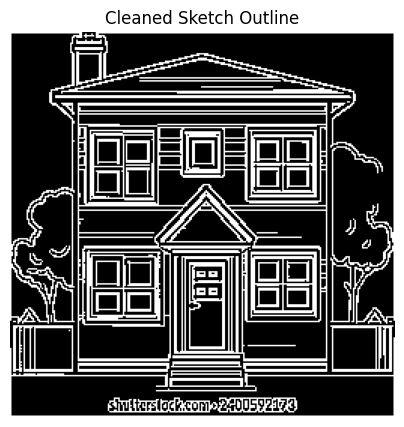

In [ ]:
from PIL import Image, ImageOps, ImageFilter
import numpy as np
import matplotlib.pyplot as plt

filename = list(uploaded.keys())[0]

# Load sketch and remove small brightness variations
img = Image.open(filename).convert("L")
img = ImageOps.autocontrast(img)
img = img.resize((256, 256), Image.Resampling.LANCZOS)

# Detect edges
edges = img.filter(ImageFilter.FIND_EDGES)
edges = ImageOps.autocontrast(edges)

# Make white edges on black background
edges = edges.point(lambda p: 255 if p > 55 else 0)

plt.figure(figsize=(5, 5))
plt.imshow(edges, cmap="gray")
plt.title("Cleaned Sketch Outline")
plt.axis("off")
plt.show()

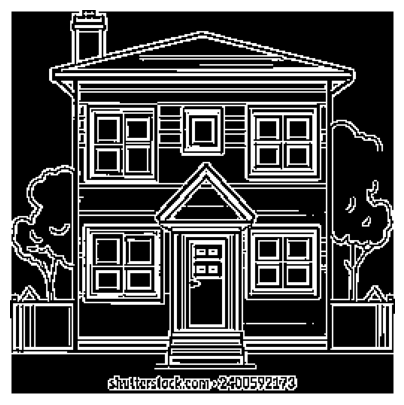

In [ ]:
from PIL import Image, ImageOps, ImageFilter
import matplotlib.pyplot as plt

filename = list(uploaded.keys())[0]

img = Image.open(filename).convert("L")
img = img.resize((256, 256), Image.Resampling.LANCZOS)
img = ImageOps.autocontrast(img)

# Thin edge detection — no MaxFilter
edges = img.filter(ImageFilter.FIND_EDGES)
edges = ImageOps.autocontrast(edges)
edges = edges.point(lambda p: 255 if p > 45 else 0)

plt.figure(figsize=(5, 5))
plt.imshow(edges, cmap="gray")
plt.axis("off")
plt.show()

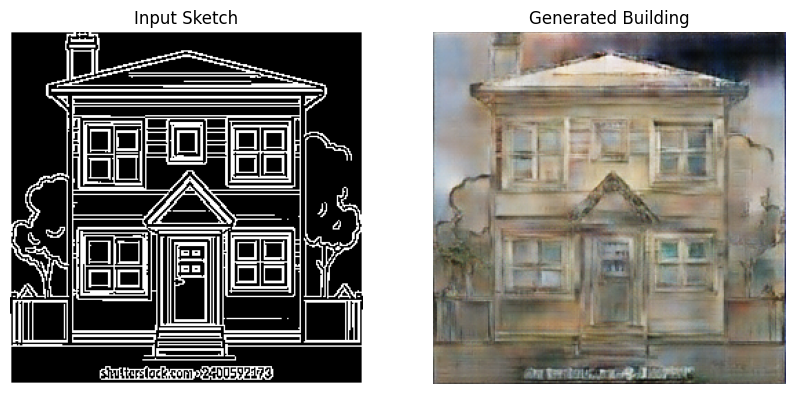

Saved: /content/generated_house.png


In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

# Convert the cleaned outline into model input
arr = np.array(edges.convert("RGB")).astype(np.float32)
arr = arr / 127.5 - 1.0

input_tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)

# Generate the building
G.eval()
with torch.no_grad():
    output = G(input_tensor.to(device))

# Convert output to an image
output = output[0].detach().cpu().clamp(-1, 1)
output = ((output + 1) * 127.5).byte()
generated = output.permute(1, 2, 0).numpy()

# Show input and generated result
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(edges, cmap="gray")
plt.title("Input Sketch")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(generated)
plt.title("Generated Building")
plt.axis("off")

plt.show()

# Save the result
Image.fromarray(generated).save("/content/generated_house.png")
print("Saved: /content/generated_house.png")

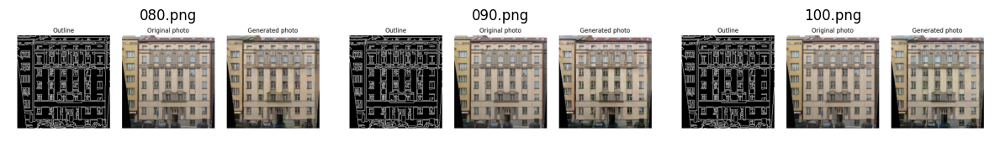

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

paths = [
    "/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_080.png",
    "/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_090.png",
    "/content/drive/MyDrive/Pix2Pix_Project/samples/epoch_100.png"
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, path in zip(axes, paths):
    img = Image.open(path)
    ax.imshow(img)
    ax.set_title(path.split("epoch_")[-1])
    ax.axis("off")

plt.tight_layout()
plt.show()

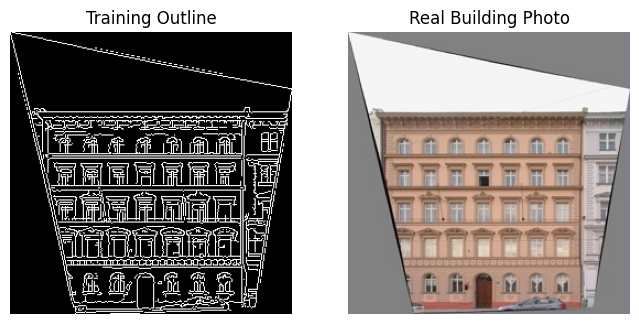

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

base = "/content/drive/MyDrive/Pix2Pix_Project"

outline = Image.open(
    f"{base}/outlines/building_0511.png"
)
photo = Image.open(
    f"{base}/building_photos/building_0511.png"
)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(outline)
plt.title("Training Outline")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(photo)
plt.title("Real Building Photo")
plt.axis("off")

plt.show()

Saving drawinghome.png to drawinghome (3).png


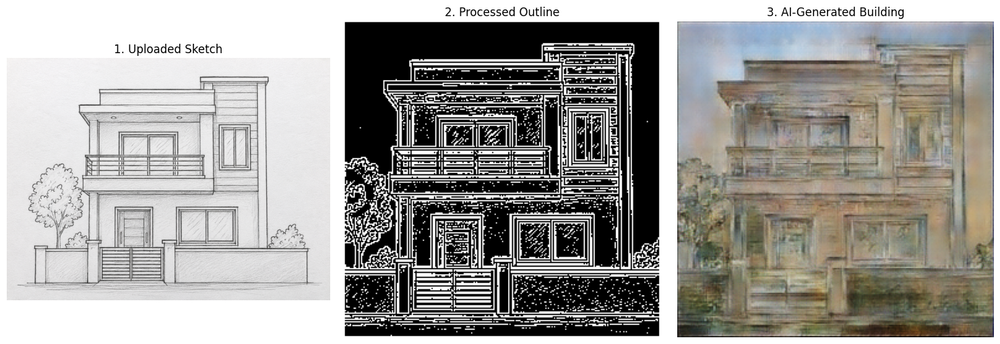

In [ ]:

from google.colab import files
from PIL import Image, ImageOps, ImageFilter
import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Upload your sketch
uploaded = files.upload()
filename = next(iter(uploaded))

original = Image.open(filename).convert("RGB")

# 2. Prepare the sketch
img = ImageOps.fit(original, (256, 256))
gray = ImageOps.grayscale(img)
outline = gray.filter(ImageFilter.FIND_EDGES)
outline = ImageOps.autocontrast(outline)
outline = outline.point(lambda p: 255 if p > 35 else 0)

# 3. Convert outline into model input
arr = np.array(outline.convert("RGB")).astype(np.float32)
arr = arr / 127.5 - 1.0

input_tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)
input_tensor = input_tensor.to(device)

# 4. Generate building image
G.eval()
with torch.no_grad():
    output = G(input_tensor)

generated = output[0].detach().cpu().clamp(-1, 1)
generated = ((generated + 1) * 127.5).byte()
generated = generated.permute(1, 2, 0).numpy()

# 5. Display all three images side by side
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("1. Uploaded Sketch")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(outline, cmap="gray")
plt.title("2. Processed Outline")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(generated)
plt.title("3. AI-Generated Building")
plt.axis("off")

plt.tight_layout()
plt.show()


Saving house to house (3)


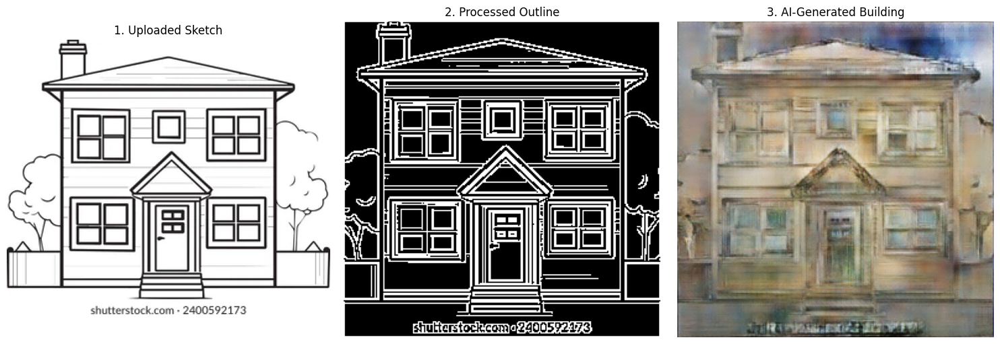

In [ ]:

from google.colab import files
from PIL import Image, ImageOps, ImageFilter
import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Upload your sketch
uploaded = files.upload()
filename = next(iter(uploaded))

original = Image.open(filename).convert("RGB")

# 2. Prepare the sketch
img = ImageOps.fit(original, (256, 256))
gray = ImageOps.grayscale(img)
outline = gray.filter(ImageFilter.FIND_EDGES)
outline = ImageOps.autocontrast(outline)
outline = outline.point(lambda p: 255 if p > 35 else 0)

# 3. Convert outline into model input
arr = np.array(outline.convert("RGB")).astype(np.float32)
arr = arr / 127.5 - 1.0

input_tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)
input_tensor = input_tensor.to(device)

# 4. Generate building image
G.eval()
with torch.no_grad():
    output = G(input_tensor)

generated = output[0].detach().cpu().clamp(-1, 1)
generated = ((generated + 1) * 127.5).byte()
generated = generated.permute(1, 2, 0).numpy()

# 5. Display all three images side by side
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("1. Uploaded Sketch")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(outline, cmap="gray")
plt.title("2. Processed Outline")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(generated)
plt.title("3. AI-Generated Building")
plt.axis("off")

plt.tight_layout()
plt.show()


Saving building.jpg to building (2).jpg


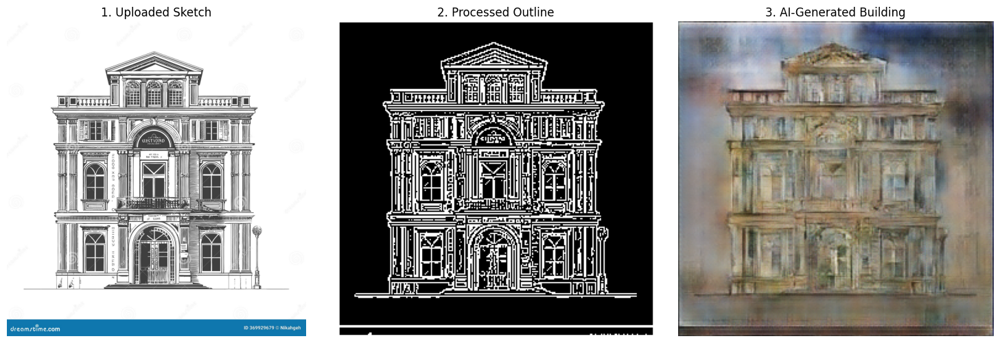

In [ ]:

from google.colab import files
from PIL import Image, ImageOps, ImageFilter
import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Upload your sketch
uploaded = files.upload()
filename = next(iter(uploaded))

original = Image.open(filename).convert("RGB")

# 2. Prepare the sketch
img = ImageOps.fit(original, (256, 256))
gray = ImageOps.grayscale(img)
outline = gray.filter(ImageFilter.FIND_EDGES)
outline = ImageOps.autocontrast(outline)
outline = outline.point(lambda p: 255 if p > 35 else 0)

# 3. Convert outline into model input
arr = np.array(outline.convert("RGB")).astype(np.float32)
arr = arr / 127.5 - 1.0

input_tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)
input_tensor = input_tensor.to(device)

# 4. Generate building image
G.eval()
with torch.no_grad():
    output = G(input_tensor)

generated = output[0].detach().cpu().clamp(-1, 1)
generated = ((generated + 1) * 127.5).byte()
generated = generated.permute(1, 2, 0).numpy()

# 5. Display all three images side by side
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("1. Uploaded Sketch")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(outline, cmap="gray")
plt.title("2. Processed Outline")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(generated)
plt.title("3. AI-Generated Building")
plt.axis("off")

plt.tight_layout()
plt.show()


Saving testhome.png to testhome (1).png


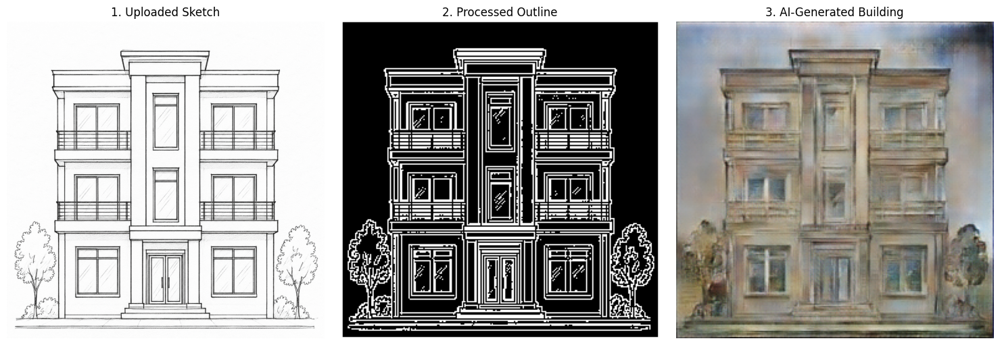

In [ ]:

from google.colab import files
from PIL import Image, ImageOps, ImageFilter
import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Upload your sketch
uploaded = files.upload()
filename = next(iter(uploaded))

original = Image.open(filename).convert("RGB")

# 2. Prepare the sketch
img = ImageOps.fit(original, (256, 256))
gray = ImageOps.grayscale(img)
outline = gray.filter(ImageFilter.FIND_EDGES)
outline = ImageOps.autocontrast(outline)
outline = outline.point(lambda p: 255 if p > 35 else 0)

# 3. Convert outline into model input
arr = np.array(outline.convert("RGB")).astype(np.float32)
arr = arr / 127.5 - 1.0

input_tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)
input_tensor = input_tensor.to(device)

# 4. Generate building image
G.eval()
with torch.no_grad():
    output = G(input_tensor)

generated = output[0].detach().cpu().clamp(-1, 1)
generated = ((generated + 1) * 127.5).byte()
generated = generated.permute(1, 2, 0).numpy()

# 5. Display all three images side by side
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("1. Uploaded Sketch")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(outline, cmap="gray")
plt.title("2. Processed Outline")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(generated)
plt.title("3. AI-Generated Building")
plt.axis("off")

plt.tight_layout()
plt.show()
